In [1]:
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Cek Dataset Kaggle

In [2]:
import os

print("Daftar dataset di /kaggle/input:")
print(os.listdir('/kaggle/input'))

Daftar dataset di /kaggle/input:
['datasets']


# Import Library

In [3]:
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import(
    Input,
    Conv2D,
    Dense,
    GlobalAveragePooling2D,
    GlobalMaxPooling2D,
    Reshape,
    Multiply,
    Add,
    Activation
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)

TensorFlow : 2.20.0
Keras      : 3.13.2


# Load Dataset

In [4]:
path_dataset = '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026'
path_dataset

'/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026'

In [5]:
# configuration
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32
SEED       = 42

# Class Create CocoaDataset

In [6]:
class CocoaDataset:
    def __init__(
        self, 
        dataset_path, 
        image_size=(224, 224), 
        batch_size=32, 
        train_size=0.80, 
        val_size=0.10, 
        test_size=0.10, 
        seed=42
    ):
        self.dataset_path = dataset_path
        self.image_size = image_size
        self.batch_size = batch_size
        self.train_size = train_size
        self.val_size = val_size
        self.test_size = test_size
        self.seed = seed

        self.class_names = ["Busuk Buah", "Helopeltis", "Kakao Sehat", "Penggerek Buah Kakao"]
        self.class_mapping = {"Busuk Buah": 0, "Helopeltis": 1, "Kakao Sehat": 2, "Penggerek Buah Kakao": 3}
        self.image_paths = []
        self.labels = []

        self.X_train = None
        self.X_val = None
        self.X_test = None

        self.y_train = None
        self.y_val = None
        self.y_test = None

    # method load dataset
    def load_dataset(self):
        valid_extension = (".jpg", ".jpeg")

        self.image_paths = []
        self.labels = []

        print("Class Mapping: ")
        for class_name, label in self.class_mapping.items():
            print(f"{label} -> {class_name}")
            
        print("\nMembaca Dataset: ")
        for class_name in self.class_names:
            class_path = os.path.join(self.dataset_path, class_name)
            if not os.path.isdir(class_path):
                raise FileNotFoundError(f"Folder tidak ditemukan: {class_path}")

            print(f"Membaca Kelas: {class_name}")
            for filename in os.listdir(class_path):
                if filename.lower().endswith(valid_extension):
                    image_path = os.path.join(class_path, filename)
                    self.image_paths.append(image_path)
                    self.labels.append(self.class_mapping[class_name])

        self.image_paths = np.array(self.image_paths)
        self.labels = np.array(self.labels)

        print("Dataset berhasil dimuat!")
        print(f"Total Gambar: {len(self.image_paths)}")
        print(f"Total Kelas: {len(self.class_names)}")
        
        return (self.image_paths, self.labels)

    # method counting the images for each class
    def count_image_for_each_class(self):
        class_counts = []
        for class_name in self.class_names:
            label = self.class_mapping[class_name]
            count = np.sum(self.labels == label)

            class_counts.append({
                "Kelas": class_name,
                "Label" : label,
                "Jumlah Gambar" : int(count)
            })
        
        return pd.DataFrame(class_counts)

    # method split dataset
    def split_dataset(self):
        total_ratio = (
            self.train_size + self.val_size + self.test_size
        )

        if not np.isclose(total_ratio, 1.0):
            raise ValueError("Total Proporsi Train, Validation dan Test Tidak Boleh Kurang Dari 1.0")

        # 80% Train
        # 20% Temporary
        self.X_train, X_temp, \
        self.y_train, y_temp = train_test_split(
            self.image_paths,
            self.labels,
            test_size=self.val_size + self.test_size,
            stratify = self.labels,
            random_state = self.seed
        )

        # Temporary -> Validation + Test
        relative_test_size = (
            self.test_size / (self.val_size + self.test_size)
        )

        self.X_val, self.X_test, \
        self.y_val, self.y_test = train_test_split(
            X_temp,
            y_temp,
            test_size=relative_test_size,
            stratify=y_temp,
            random_state=self.seed
        )

        print("\nPembagian dataset:")
        print(f"Train      : {len(self.X_train)}")
        print(f"Validation : {len(self.X_val)}")
        print(f"Test       : {len(self.X_test)}")

        return None

    # method preprocessing
    def preprocess_image(self, image_path, label):
        
        # read file
        image = tf.io.read_file(image_path)

        # change image to tensor number (array)
        image = tf.image.decode_jpeg(image, channels=3)

        # resize 224 x 224
        image = tf.image.resize(image, self.image_size)

        # change type data cast from tensor number (array) to float32
        image = tf.cast(image, tf.float32)

        # ResNet50 ImageNet preprocessing
        image = tf.keras.applications.resnet50.preprocess_input(image)

        # One-hot encoding label
        label = tf.one_hot(label, depth=len(self.class_names))

        return image, label

    # method create tensorflow dataset
    def create_dataset_tensorflow(self, image_paths, labels, shuffle=False):
        dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
        dataset = dataset.map(self.preprocess_image, num_parallel_calls=2)

        if shuffle:
            dataset = dataset.shuffle(buffer_size=min(len(image_paths), 1000), seed=self.seed)
        
        dataset = dataset.batch(self.batch_size)
        dataset = dataset.prefetch(1)

        return dataset

    # method get train, validation and test
    def get_train_val_test(self):
        train_dataset = self.create_dataset_tensorflow(self.X_train, self.y_train, shuffle=True)
        val_dataset = self.create_dataset_tensorflow(self.X_val, self.y_val, shuffle=False)
        test_dataset = self.create_dataset_tensorflow(self.X_test, self.y_test, shuffle=False)

        return(train_dataset, val_dataset, test_dataset)

In [7]:
dataset_manager = CocoaDataset(
    dataset_path=path_dataset,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    train_size=0.80,
    val_size=0.10,
    test_size=0.10,
    seed=SEED
)

In [8]:
# load dataset
dataset_manager.load_dataset()

Class Mapping: 
0 -> Busuk Buah
1 -> Helopeltis
2 -> Kakao Sehat
3 -> Penggerek Buah Kakao

Membaca Dataset: 
Membaca Kelas: Busuk Buah
Membaca Kelas: Helopeltis
Membaca Kelas: Kakao Sehat
Membaca Kelas: Penggerek Buah Kakao
Dataset berhasil dimuat!
Total Gambar: 6992
Total Kelas: 4


(array(['/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_2_busuk_buah_131.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_1_busuk_buah_324.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Busuk Buah/train_dataset_1_busuk_buah_368.jpg',
        ...,
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_1_penggerek_buah_kakao_314.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_1_penggerek_buah_kakao_531.jpg',
        '/kaggle/input/datasets/ahmadwafi/dataset-penelitian-kakao-2026/Penggerek Buah Kakao/train_dataset_2_pbk_239.jpg'],
       dtype='<U129'),
 array([0, 0, 0, ..., 3, 3, 3]))

In [9]:
# count image for each class
dataset_manager.count_image_for_each_class()

,Kelas,Label,Jumlah Gambar
0,Busuk Buah,0,1748
1,Helopeltis,1,1748
2,Kakao Sehat,2,1748
3,Penggerek Buah Kakao,3,1748


In [10]:
# split dataset
dataset_manager.split_dataset()


Pembagian dataset:
Train      : 5593
Validation : 699
Test       : 700


In [11]:
# create tensorflow dataset
train_dataset, val_dataset, test_dataset=(dataset_manager.get_train_val_test())

I0000 00:00:1788608172.907677      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788608172.911134      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [12]:
print(type(train_dataset))
print(type(val_dataset))
print(type(test_dataset))

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>
<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


# Class Convolutional Block Attention Module (CBAM)

In [13]:
class ConvolutionalBlockAttentionModule(layers.Layer):
    def __init__(
        self,
        reduction_ratio=16,
        spatial_kernel_size=7,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.reduction_ratio = reduction_ratio
        self.spatial_kernel_size = spatial_kernel_size

    # method build
    def build(self, input_shape):
        channel = input_shape[-1]
        hidden_channel = max(channel // self.reduction_ratio, 1)

        # shared MLP
        self.shared_dense_1 = Dense(hidden_channel, activation="relu", use_bias=True)

        self.shared_dense_2 = Dense(channel, use_bias=True)

        # Spatial Attention
        self.spatial_conv = Conv2D(
            filters=1,
            kernel_size=self.spatial_kernel_size,
            padding="same",
            activation="sigmoid",
            use_bias=False
        )

        super().build(input_shape)

    # method channel attention
    def channel_attention(self, x):
        # Average Pooling
        avg_pool = GlobalAveragePooling2D()(x)
        avg_pool = Reshape((1, 1, x.shape[-1]))(avg_pool)

        # Max Pooling
        max_pool = GlobalMaxPooling2D()(x)
        max_pool = Reshape((1, 1, x.shape[-1]))(max_pool)

        # Shared MLP - Average
        avg_out = self.shared_dense_1(avg_pool)
        avg_out = self.shared_dense_2(avg_out)

        # Shared MLP - Max
        max_out = self.shared_dense_1(max_pool)
        max_out = self.shared_dense_2(max_out)

        # Combine
        attention = Add()([avg_out, max_out])
        attention = Activation("sigmoid")(attention)

        # Apply Channel Attention
        x = Multiply()([x, attention])

        return x

    # method spatial attention
    def spatial_attention(self, x):
        # Average pooling across channel
        avg_pool = tf.reduce_mean(x, axis=-1, keepdims=True)

        # Max pooling across channel
        max_pool = tf.reduce_max(x, axis=-1, keepdims=True)

        # Concatenate
        concat = tf.concat([avg_pool, max_pool], axis=-1)

        # Spatial Attention
        attention = self.spatial_conv(concat)

        # Apply Spatial Attention
        x = Multiply()([x, attention])

        return x

    # method call channel attention and spatial attention
    def call(self, inputs):
        # Channel Attention
        x = self.channel_attention(inputs)

        # Spatial Attention
        x = self.spatial_attention(x)

        return x

    # method get config
    def get_config(self):
        config = super().get_config()
        config.update({
            "reduction_ratio": self.reduction_ratio,
            "spatial_kernel_size": self.spatial_kernel_size
        })

        return config

# Class ResNet50CBAM

In [14]:
class ResNet50CBAM:
    def __init__(
        self,
        input_shape=(224,224,3),
        num_classes=4,
        reduction_ratio=16,
        spatial_kernel_size=7,
        dropout_rate=0.5
    ):
        self.input_shape = input_shape
        self.num_classes = num_classes

        self.reduction_ratio = reduction_ratio
        self.spatial_kernel_size = spatial_kernel_size

        self.dropout_rate = dropout_rate
        
    # method build model resnet50-cbam
    def build(self):
        # ===================================
        # 1. RESNET50 PRETRAINED IMAGENET
        # ===================================

        backbone = tf.keras.applications.ResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=self.input_shape
        )

        # ===========================================
        # 2. MENGAMBIL OUTPUT SETIAP RESIDUAL STAGE
        # ===========================================

        conv2_output = backbone.get_layer("conv2_block3_out").output
        conv3_output = backbone.get_layer("conv3_block4_out").output
        conv4_output = backbone.get_layer("conv4_block6_out").output
        conv5_output = backbone.get_layer("conv5_block3_out").output


        # =====================================================
        # 3. BUAT SUBMODEL UNTUK SETIAP BAGIAN DARI RESNET50 
        # =====================================================

        # Stem + Conv2_x
        stem_conv2 = tf.keras.Model(inputs=backbone.input, outputs=conv2_output, name="resnet50_stem_conv2")

        # Conv3_x
        stage3 = tf.keras.Model(inputs=conv2_output, outputs=conv3_output, name="resnet50_conv3")

        # Conv4_x
        stage4 = tf.keras.Model(inputs=conv3_output, outputs=conv4_output, name="resnet50_conv4")

        # Conv5_x
        stage5 = tf.keras.Model(inputs=conv4_output, outputs=conv5_output, name="resnet50_conv5")

        # ==============
        # 4. INPUT
        # ==============

        inputs = Input(shape=self.input_shape, name="input_image")

        # ====================================
        # 5. STEM + CONV2_X PRETRAINED
        # ====================================

        x = stem_conv2(inputs)

        # ====================================
        # 6. MODUL CBAM AFTER CONV2_X
        # ====================================

        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv2"
        )(x)

        # ====================================
        # 7. CONV3_X PRETRAINED
        # ====================================

        x = stage3(x)

        # ====================================
        # 8. MODUL CBAM AFTER CONV3_X
        # ====================================

        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv3"
        )(x)

        # ====================================
        # 9. CONV4_X PRETRAINED
        # ====================================

        x = stage4(x)

        # ====================================
        # 10. MODUL CBAM AFTER CONV4_X
        # ====================================

        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv4"
        )(x)

        # ====================================
        # 11. CONV5_X PRETRAINED
        # ====================================

        x = stage5(x)

        # ====================================
        # 12. MODUL CBAM AFTER CONV5_X
        # ====================================

        x = ConvolutionalBlockAttentionModule(
            reduction_ratio=self.reduction_ratio,
            spatial_kernel_size=self.spatial_kernel_size,
            name="cbam_conv5"
        )(x)

        # ====================================
        # 13. CLASSIFIER
        # ====================================

        x = GlobalAveragePooling2D(
            name="global_average_pooling"
        )(x)
        x = Dense(256, activation="relu", name="fc1")(x)
        x = layers.Dropout(self.dropout_rate, name="dropout")(x)
        outputs = Dense(self.num_classes, activation="softmax", name="classifier")(x)

        # ====================================
        # 14. FINAL MODEL
        # ====================================

        model = tf.keras.Model(inputs=inputs, outputs=outputs, name="ResNet50_Pretrained_CBAM")
        
        return model, backbone

In [15]:
resnet50_cbam = ResNet50CBAM(
    input_shape=(224,224,3),
    num_classes=4,
    reduction_ratio=16,
    spatial_kernel_size=7,
    dropout_rate=0.5
)

model_resnet50_cbam, backbone = resnet50_cbam.build()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [16]:
print(type(backbone))
print(backbone.name)

<class 'keras.src.models.functional.Functional'>
resnet50


# Freeze ResNet50 (Tahap 1)

In [17]:
# ====================================
# FREEZE BACKBONE RESNET50
# ====================================

for layer in backbone.layers:
    layer.trainable=False

print("Backbone ResNet50 sudah berhasil di-freeze.")
print("Trainable parameters: ",
     np.sum([
         np.prod(v.shape)
         for v in model_resnet50_cbam.trainable_weights
     ]))
print("Non-trainable parameters: ",
     np.sum([
         np.prod(v.shape)
         for v in model_resnet50_cbam.non_trainable_weights
     ]))

Backbone ResNet50 sudah berhasil di-freeze.
Trainable parameters:  1226364
Non-trainable parameters:  23587712


# Compile Model (Tahap 1)

In [18]:
model_resnet50_cbam.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
model_resnet50_cbam.summary()

Model: "ResNet50_Pretrained_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_stem_conv2             │ (None, 56, 56, 256)    │       229,760 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv2                      │ (None, 56, 56, 256)    │         8,562 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv3 (Functional)     │ (None, 28, 28, 512)    │     1,230,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv3                      │ (None, 28, 28, 512)    │        33,410 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv4 (Functional)     │ (None, 14, 14, 1024)   │     7,129,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv4                      │ (None, 14, 14, 1024)   │       132,258 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50_conv5 (Functional)     │ (None, 7, 7, 2048)     │    14,998,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam_conv5                      │ (None, 7, 7, 2048)     │       526,562 │
│ (ConvolutionalBlockAttentionMo… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,814,076 (94.66 MB)

 Trainable params: 1,226,364 (4.68 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

# Callback (Tahap 1)

In [20]:
checkpoint_tahap_1 = tf.keras.callbacks.ModelCheckpoint(
    "best_resnet50_cbam.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping_tahap_1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_tahap_1 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [21]:
callbacks = [checkpoint_tahap_1, early_stopping_tahap_1, reduce_lr_tahap_1]

# Training Model (Tahap 1)

In [22]:
history_resnet50_cbam_tahap_1 = model_resnet50_cbam.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30


I0000 00:00:1788608276.079287     129 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step - accuracy: 0.4438 - loss: 1.1758
Epoch 1: val_accuracy improved from None to 0.85980, saving model to best_resnet50_cbam.keras

Epoch 1: finished saving model to best_resnet50_cbam.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 123s 475ms/step - accuracy: 0.6238 - loss: 0.8860 - val_accuracy: 0.8598 - val_loss: 0.3786 - learning_rate: 1.0000e-04
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.8527 - loss: 0.4068
Epoch 2: val_accuracy improved from 0.85980 to 0.90987, saving model to best_resnet50_cbam.keras

Epoch 2: finished saving model to best_resnet50_cbam.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 36s 178ms/step - accuracy: 0.8723 - loss: 0.3634 - val_accuracy: 0.9099 - val_loss: 0.2667 - learning_rate: 1.0000e-04
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.9084 - loss: 0.2782
Epoch 3: val_accuracy improved from 0.90987 to 0.93562, saving model to best_resnet50_cbam.keras

Epoch 3: finished saving model to best_re

In [23]:
# Fungsi untuk memplot akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Akurasi Pelatihan')
    plt.plot(history.history['val_accuracy'], label='Akurasi Validasi')
    plt.title('Akurasi Model')
    plt.xlabel('Epoch')
    plt.ylabel('Akurasi')
    plt.legend()

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Loss Pelatihan')
    plt.plot(history.history['val_loss'], label='Loss Validasi')
    plt.title('Loss Model')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

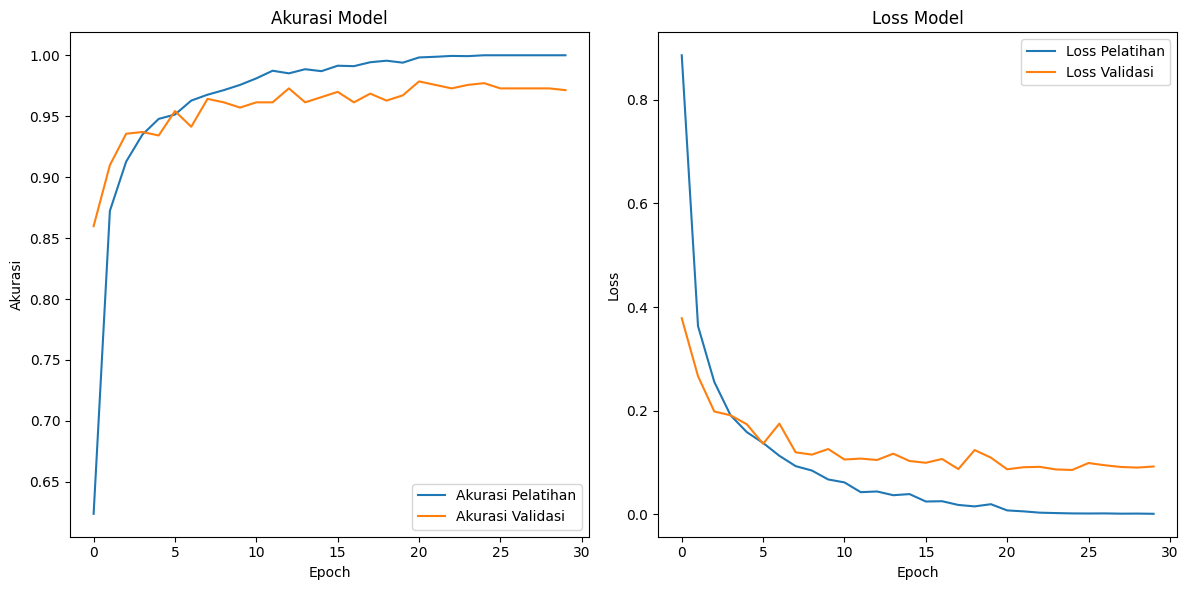

In [24]:
# Plot akurasi dan loss
plot_history(history_resnet50_cbam_tahap_1)

# Tahap 2 Fine Tunning

# Unfreeze Conv4_x + Conv5_x

In [25]:
# ====================================
# FINE-TUNING
# UNFREEZE CONV4_X DAN CONV5_X
# ====================================

for layer in backbone.layers:
    if layer.name.startswith("conv4_") or layer.name.startswith("conv5_"):
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

print("Trainable backbone layers:")

for layer in backbone.layers:
    if layer.trainable:
        print(layer.name)

Trainable backbone layers:
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
conv4_block2_2_relu
conv4_block2_3_conv
conv4_block2_add
conv4_block2_out
conv4_block3_1_conv
conv4_block3_1_relu
conv4_block3_2_conv
conv4_block3_2_relu
conv4_block3_3_conv
conv4_block3_add
conv4_block3_out
conv4_block4_1_conv
conv4_block4_1_relu
conv4_block4_2_conv
conv4_block4_2_relu
conv4_block4_3_conv
conv4_block4_add
conv4_block4_out
conv4_block5_1_conv
conv4_block5_1_relu
conv4_block5_2_conv
conv4_block5_2_relu
conv4_block5_3_conv
conv4_block5_add
conv4_block5_out
conv4_block6_1_conv
conv4_block6_1_relu
conv4_block6_2_conv
conv4_block6_2_relu
conv4_block6_3_conv
conv4_block6_add
conv4_block6_out
conv5_block1_1_conv
conv5_block1_1_relu
conv5_block1_2_conv
conv5_block1_2_relu
conv5_block1_0_conv
conv5_block1_3_conv
conv5_block1_add
conv5_block1

# Compile Ulang dengan Learning Rate yang kecil

In [26]:
model_resnet50_cbam.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Callback Tahap 2

In [27]:
checkpoint_tahap_2 = tf.keras.callbacks.ModelCheckpoint(
    "best_resnet50_cbam_finetuned.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping_tahap_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_tahap_2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [28]:
callbacks_stage_2 = [checkpoint_tahap_2, early_stopping_tahap_2, reduce_lr_tahap_2]

In [29]:
print("Train dataset:")
print(train_dataset)

print("\nValidation dataset:")
print(val_dataset)

print("\nTrainable weights:")
print(len(model_resnet50_cbam.trainable_weights))

print("\nNon-trainable weights:")
print(len(model_resnet50_cbam.non_trainable_weights))

Train dataset:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>

Validation dataset:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>

Trainable weights:
82

Non-trainable weights:
260


In [30]:
print("\n===== DATASET CHECK =====")

for images, labels in train_dataset.take(1):
    print("Train images :", images.shape)
    print("Train labels :", labels.shape)

for images, labels in val_dataset.take(1):
    print("Val images   :", images.shape)
    print("Val labels   :", labels.shape)


===== DATASET CHECK =====
Train images : (32, 224, 224, 3)
Train labels : (32, 4)
Val images   : (32, 224, 224, 3)
Val labels   : (32, 4)


# Training Fine-Tuning

In [31]:
history_resnet50_cbam_tahap_2 = model_resnet50_cbam.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=callbacks_stage_2
)

Epoch 1/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.9661 - loss: 0.1100
Epoch 1: val_accuracy improved from None to 0.96567, saving model to best_resnet50_cbam_finetuned.keras

Epoch 1: finished saving model to best_resnet50_cbam_finetuned.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 108s 398ms/step - accuracy: 0.9769 - loss: 0.0718 - val_accuracy: 0.9657 - val_loss: 0.1250 - learning_rate: 1.0000e-05
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9931 - loss: 0.0236
Epoch 2: val_accuracy did not improve from 0.96567
175/175 ━━━━━━━━━━━━━━━━━━━━ 44s 226ms/step - accuracy: 0.9907 - loss: 0.0303 - val_accuracy: 0.9428 - val_loss: 0.1679 - learning_rate: 1.0000e-05
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9859 - loss: 0.0420
Epoch 3: val_accuracy improved from 0.96567 to 0.98569, saving model to best_resnet50_cbam_finetuned.keras

Epoch 3: finished saving model to best_resnet50_cbam_finetuned.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 46s 235m

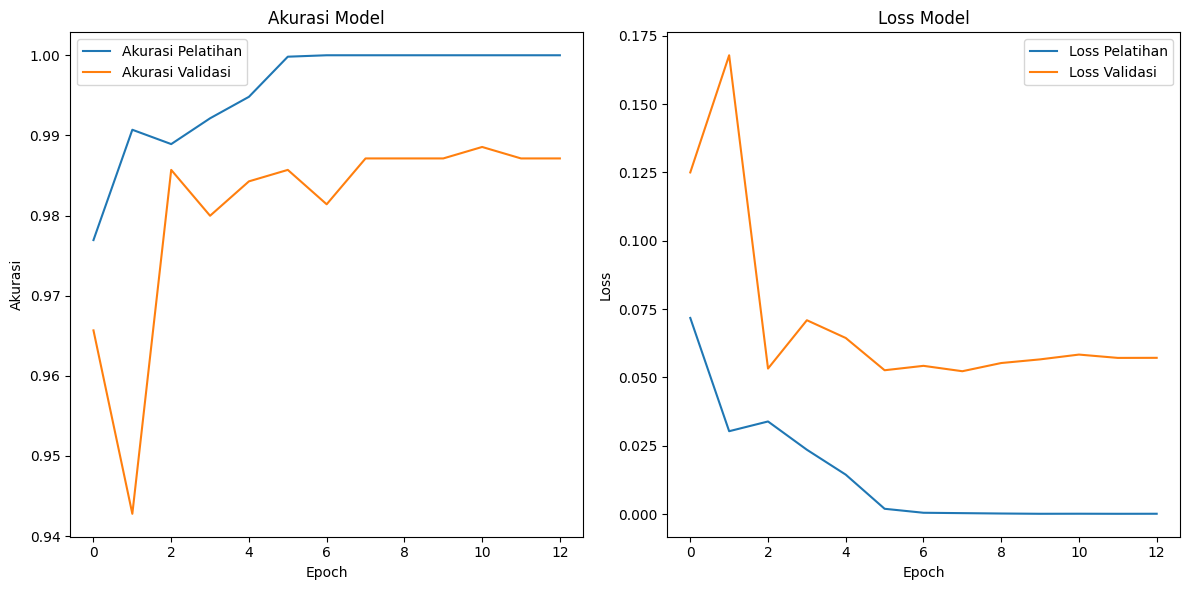

In [32]:
# Plot akurasi dan loss
plot_history(history_resnet50_cbam_tahap_2)

In [33]:
model_resnet50_cbam = tf.keras.models.load_model(
    "best_resnet50_cbam_finetuned.keras",
    custom_objects={
        "ConvolutionalBlockAttentionModule":
            ConvolutionalBlockAttentionModule
    }
)

# Testing

In [34]:
# clas names
class_names = [
    "Busuk Buah",
    "Helopeltis",
    "Kakao Sehat",
    "Penggerek Buah Kakao"
]

# prediksi pada data test
y_pred_prob = model_resnet50_cbam.predict(test_dataset, verbose=1)

# convert probabilities -> label class
y_pred = np.argmax(y_pred_prob, axis=1)

22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 685ms/step


In [35]:
# mengambil label sebenarnya dari test_dataset
y_true = []

for images, labels in test_dataset:
    labels = labels.numpy()

    # One-hot -> integer label
    labels = np.argmax(labels, axis=1)

    y_true.extend(labels)

y_true = np.array(y_true)

In [36]:
# periksa bentuk data
print("Shape y_true     :", y_true.shape)
print("Shape y_pred     :", y_pred.shape)

print("Contoh y_true    :", y_true[:10])
print("Contoh y_pred    :", y_pred[:10])

Shape y_true     : (700,)
Shape y_pred     : (700,)
Contoh y_true    : [2 2 1 3 2 3 2 0 2 1]
Contoh y_pred    : [2 2 1 3 2 3 2 0 2 1]


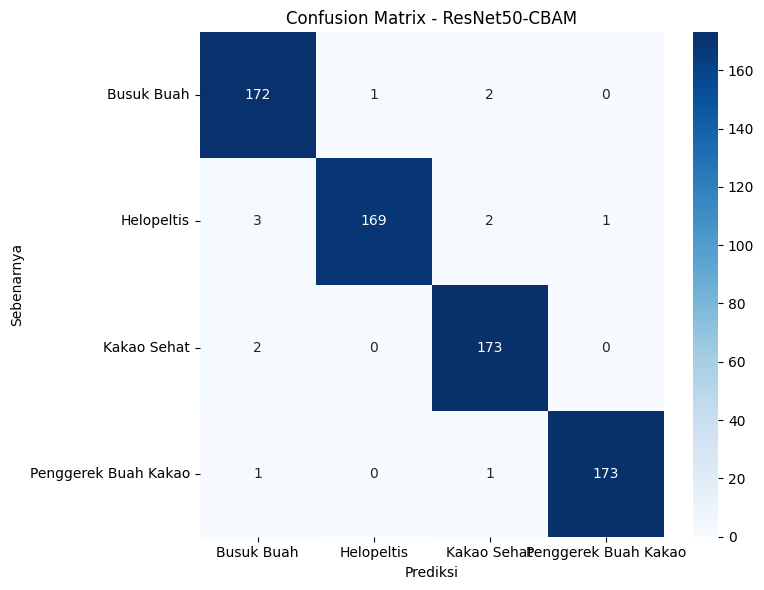

In [37]:
# confusion matrix
cm = confusion_matrix(y_true, y_pred)

# visualisasi confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix - ResNet50-CBAM")
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.tight_layout()
plt.show()

In [38]:
# accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 98.14%


In [39]:
# classification report
print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

Classification Report:

                      precision    recall  f1-score   support

          Busuk Buah     0.9663    0.9829    0.9745       175
          Helopeltis     0.9941    0.9657    0.9797       175
         Kakao Sehat     0.9719    0.9886    0.9802       175
Penggerek Buah Kakao     0.9943    0.9886    0.9914       175

            accuracy                         0.9814       700
           macro avg     0.9816    0.9814    0.9814       700
        weighted avg     0.9816    0.9814    0.9814       700



In [40]:
# Save Model
model_resnet50_cbam.save("/kaggle/working/model_resnet50_cbam_finetuned.keras")